# 5. Implémentation de l'algorithme

**Le cas séparable sur les données d'Iris**

Les sections précédentes ont construit le problème, montré qu'il admet une solution unique et l'ont résolu par le lagrangien et les conditions KKT. Cette section fait tourner tout cela sur de vraies données et vérifie, chiffres à l'appui, les deux résultats annoncés :

1. **la parcimonie** — seuls les vecteurs de support déterminent l'hyperplan 
2. **l'écart complémentaire** — $\alpha_i > 0$ si et seulement si le point est sur le bord de la marge

On reste dans le cas séparable et avec un noyau linéaire d'un bout à l'autre.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore")
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, StratifiedKFold

POS, NEG = "#2b6cb0", "#dd6b20"
pli = StratifiedKFold(5, shuffle=True, random_state=0)
DUR = 1e6                      # un C très grand reproduit la marge dure

## 5.1 Les données et la solution

In [88]:
X, y = load_iris(return_X_y=True)
X_acp = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))

masque = (y == 0) | (y == 1)
X2 = X_acp[masque]
# setosa = -1, versicolor = +1
y2 = np.where(y[masque] == 0, -1, 1)          

modele = SVC(kernel="linear", C=DUR).fit(X2, y2)

print(f"erreurs d'apprentissage : {int((modele.predict(X2) != y2).sum())}")  #0 = donc séparables
print(f"vecteurs de support     : {modele.support_.size} sur {len(y2)}")
print(f"largeur de la marge     : {2 / np.linalg.norm(modele.coef_):.3f}")

erreurs d'apprentissage : 0
vecteurs de support     : 3 sur 100
largeur de la marge     : 1.362


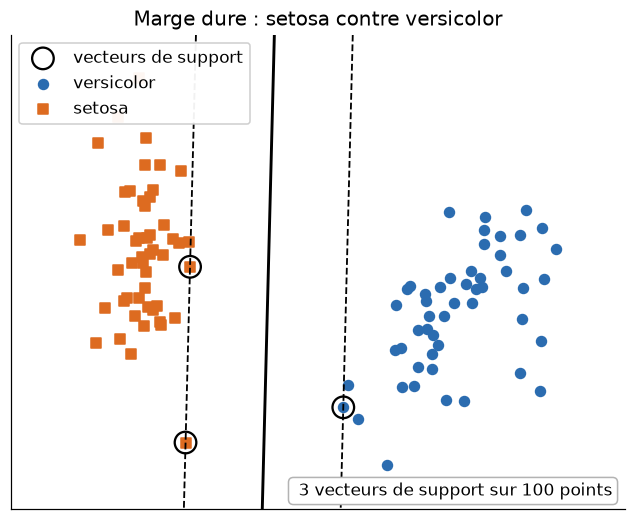

In [76]:
def tracer(modele, X, y, ax, titre):
    pad = 0.6
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    b0, b1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, 400), np.linspace(b0, b1, 400))
    Z = modele.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.2, 1.9, 1.2])
    ax.scatter(X[modele.support_, 0], X[modele.support_, 1], s=200, facecolors="none", edgecolors="k", linewidths=1.5,
               label="vecteurs de support")
    ax.scatter(X[y == 1, 0],  X[y == 1, 1],  c=POS, s=42, label="versicolor")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c=NEG, s=42, marker="s", label="setosa")
    ax.set_title(titre, fontsize=13); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(x0, x1); ax.set_ylim(b0, b1)


fig, ax = plt.subplots(figsize=(7.2, 5.6))
tracer(modele, X2, y2, ax, "Marge dure : setosa contre versicolor")
ax.legend(loc="upper left", fontsize=11, framealpha=0.95)
ax.text(0.98, 0.02, f" {modele.support_.size} vecteurs de support sur {len(y2)} points", transform=ax.transAxes, ha="right", 
        va="bottom", fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.7"))
plt.show()

Les multiplicateurs permettent de la vérifier directement. L'écart complémentaire $\alpha_i\,[\,y_i(w^\top x_i + b) - 1\,] = 0$ est un produit nul : pour chaque point, l'un des deux facteurs doit s'annuler.

In [79]:
alpha = np.zeros(len(y2))
alpha[modele.support_] = np.abs(modele.dual_coef_[0])   # sklearn stocke y_i * alpha_i
marges = y2 * modele.decision_function(X2)

print("  i      alpha_i     y_i f(x_i)    statut")
print("-" * 52)
for i in list(modele.support_) + list(np.argsort(-marges)[:3]):
    print(f"{i:3d}    {alpha[i]:9.5f}    {marges[i]:8.4f}    {{}}",
             "SUR le bord de la marge" if alpha[i] > 0 else "hors de la marge")

print()
print(f"alpha > 0 : {(alpha > 0).sum()} points, y f(x) entre {marges[alpha > 0].min():.4f} et {marges[alpha > 0].max():.4f}")
print(f"alpha = 0 : {(alpha == 0).sum()} points, y f(x) au minimum {marges[alpha == 0].min():.4f}")

  i      alpha_i     y_i f(x_i)    statut
----------------------------------------------------
 23      0.22537      0.9997    {} SUR le bord de la marge
 41      0.85200      1.0006    {} SUR le bord de la marge
 57      1.07736      1.0003    {} SUR le bord de la marge
 77      0.00000      3.6583    {} hors de la marge
 76      0.00000      3.5183    {} hors de la marge
 68      0.00000      3.5086    {} hors de la marge

alpha > 0 : 3 points, y f(x) entre 0.9997 et 1.0006
alpha = 0 : 97 points, y f(x) au minimum 1.0267


## 5.2 Le rôle de $C$, et la validation croisée

On le fait varier sur six ordres de grandeur, et on mesure à chaque fois deux choses : la géométrie du modèle, largeur de la marge et nombre de vecteurs de support et sa performance, estimée par validation croisée à cinq plis.

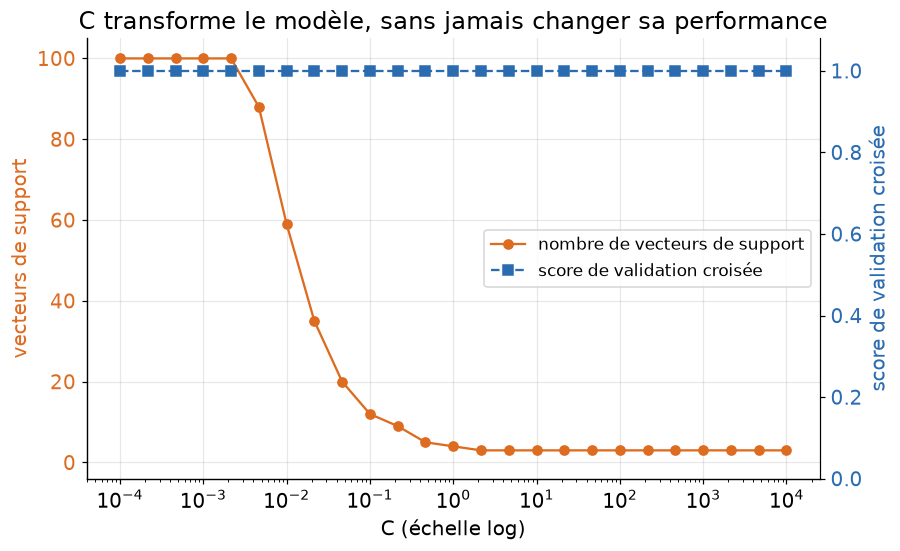

vecteurs de support : de 100 (C minuscule) à 3 (C grand)
largeur de la marge : de 140.5 à 1.36
validation croisée  : constante à 1.000 sur toute la plage


In [81]:
Cs = np.logspace(-4, 4, 25)
nsv, largeur, vc = [], [], []

for c in Cs:
    m = SVC(kernel="linear", C=c).fit(X2, y2)
    nsv.append(m.support_.size)
    largeur.append(2 / np.linalg.norm(m.coef_))
    vc.append(cross_val_score(SVC(kernel="linear", C=c), X2, y2, cv=pli).mean())

nsv, largeur, vc = np.array(nsv), np.array(largeur), np.array(vc)

fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.semilogx(Cs, nsv, "o-", color=NEG, label="nombre de vecteurs de support")
ax.set_xlabel("C (échelle log)")
ax.set_ylabel("vecteurs de support", color=NEG)
ax.tick_params(axis="y", labelcolor=NEG)
ax.set_ylim(-4, 105); ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.semilogx(Cs, vc, "s--", color=POS, label="score de validation croisée")
ax2.set_ylabel("score de validation croisée", color=POS)
ax2.tick_params(axis="y", labelcolor=POS)
ax2.set_ylim(0, 1.08)
ax2.spines["right"].set_visible(True)

lignes = ax.get_lines() + ax2.get_lines()
ax.legend(lignes, [l.get_label() for l in lignes], fontsize=11, loc="center right")
ax.set_title("C transforme le modèle, sans jamais changer sa performance")
plt.show()

print(f"vecteurs de support : de {nsv.max()} (C minuscule) à {nsv.min()} (C grand)")
print(f"largeur de la marge : de {largeur.max():.1f} à {largeur.min():.2f}")
print(f"validation croisée  : constante à {vc.mean():.3f} sur toute la plage")

In [82]:
print("   C        marge    vecteurs de support")
print("-" * 42)
for c in [1e-3, 1e-2, 0.1, 1, 10, 100, 1e4]:
    m = SVC(kernel="linear", C=c).fit(X2, y2)
    print(f"{c:7g}    {2 / np.linalg.norm(m.coef_):7.2f}      {m.support_.size:3d}")

   C        marge    vecteurs de support
------------------------------------------
  0.001      14.05      100
   0.01       2.88       59
    0.1       2.01       12
      1       1.40        4
     10       1.36        3
    100       1.36        3
  10000       1.36        3


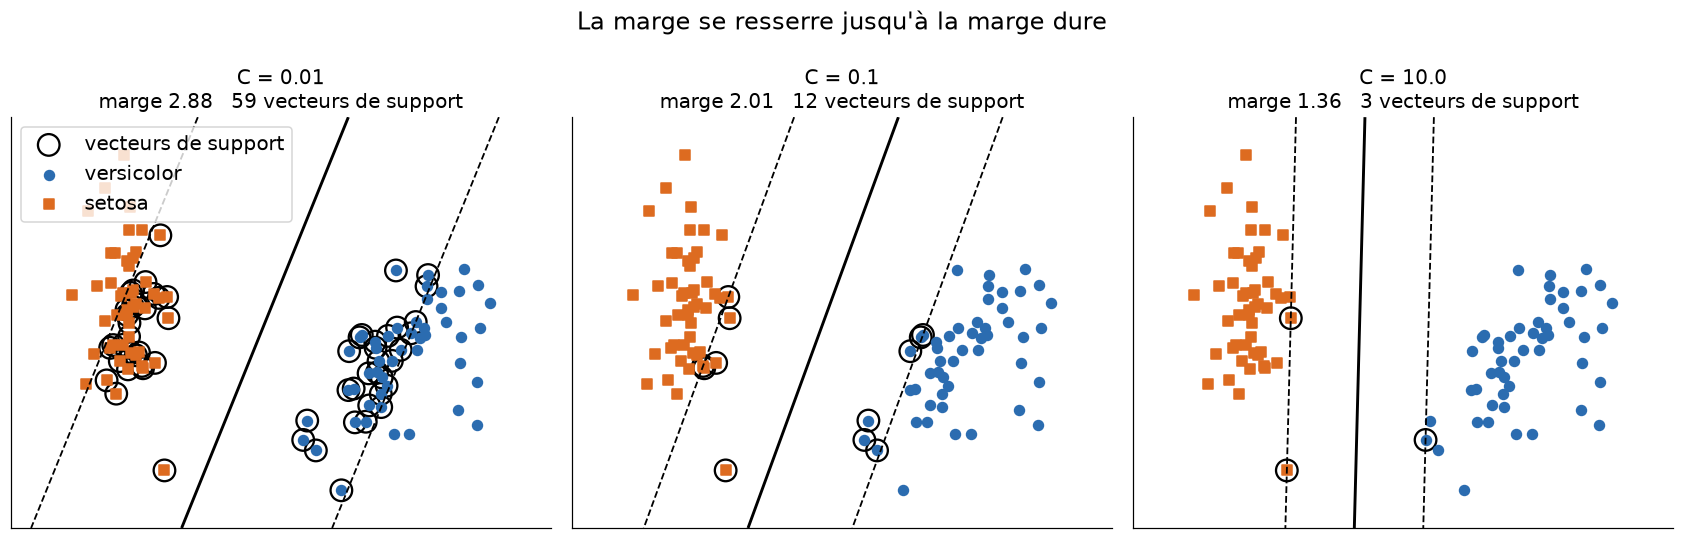

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5))
for ax, c in zip(axes, [0.01, 0.1, 10.0]):
    m = SVC(kernel="linear", C=c).fit(X2, y2)
    tracer(m, X2, y2, ax,
           f"C = {c}\nmarge {2 / np.linalg.norm(m.coef_):.2f}   {m.support_.size} vecteurs de support")
axes[0].legend(loc="upper left")
fig.suptitle("La marge se resserre jusqu'à la marge dure")
fig.tight_layout()
plt.show()